# PV anomaly detection with weather-normalised baselines

**Question an O&M team asks every morning:** which inverters lost energy yesterday,
why, and how much?

Raw output cannot answer it: it drops on a cloudy day *and* on a day with a blown
string fuse. This notebook compares each inverter's output with what **the weather
should have produced**, learned from the plant's own history, and turns the gap into
alarms with a reason and an energy loss in kWh.

| Section | What it shows |
|---|---|
| 1 · Method | weather baseline, plant topology `TT_II_SS`, detection rules |
| 2 · Synthetic plant | faults injected on purpose, so precision and recall can be measured |
| 3 · Detection limit | how big a loss must be before it is caught |
| 4 · Real plants | two plants from Kaggle (India, 22 inverters each, 34 days) |
| 5 · Limitations | what this does not prove |

All functions live in [`pvad.py`](pvad.py); tests in [`test_pvad.py`](test_pvad.py).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import pvad

INK, MUTED, ACCENT, ALERT = "#1f2933", "#8a94a3", "#2563eb", "#dc2626"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.titlelocation": "left", "axes.titlecolor": INK, "figure.dpi": 110})
pd.set_option("display.precision", 3)

## 1 · Method

### Weather baseline
For each inverter, a robust (Huber) regression learns on the first **14 days**:

$$P \approx f\big(G,\; G\cdot(T_{mod}-25),\; G^2\big)$$

This is the PV power equation $P \approx k\,G\,(1+\gamma\,(T_{mod}-25))$ expanded,
plus a mild non-linearity (low light, clipping). The coefficients are physical, so two
weeks of data are enough. The **performance index** $PI = P_{measured}/P_{expected}$ is
~1.0 on a cloudy day for a healthy inverter, and ~0.95 on a clear day with one string open.

### Plant topology and fault attribution
In the field I name every asset by where it hangs:

```
TT_II_SS    TT = transformer (01-99) · II = inverter (01-99) · SS = string (01-99)
01_07_14    string 14 of inverter 07 on transformer 01
```

A fault is attributed to the **lowest level that explains it**. When **≥ 80% of the
children drop at the same moment**, the cause is the parent: all strings of an inverter
mean the inverter, all inverters of a transformer mean the transformer, and the whole
plant means the grid, curtailment or the logger. Without this, one grid trip becomes 22
inverter alarms. This notebook works at inverter level (`TT_II`). Public data has no
topology, so every inverter sits on transformer `01`.

### Detection rules
One function per rule in `pvad.py`, each in plain O&M terms:

| Rule | Fires when | Catches |
|---|---|---|
| Plant event | ≥ 80% of inverters drop together | grid trip, curtailment, logger outage (reported once) |
| Zero output in daylight | ≥ 1 h at zero with the sun up | trip, open breaker |
| No data | ≥ 1 h without a reading | comms / logger fault |
| New fault | PI < 93% of the inverter's **own best days** (P90, clear sky) *and* < 93% of the fleet | string loss, soiling, failed MPPT |
| Chronic | typically < 90% of the **best peers** (fleet P90) | an inverter that was always low |
| Step report *(information)* | PI vs. fleet drops ≥ 3% and stays | dates the day a string opened |

## 2 · Synthetic plant with labelled faults

Public PV datasets have no fault labels, so detection quality can only be measured on
faults injected on purpose. The synthetic plant has:
- the same schema as Kaggle: 22 inverters, 34 days at 15 min;
- realistic noise: clouds hit each block differently from the single weather sensor;
- clipping at the inverter AC rating;
- a **2 h grid trip** on day 23.

In [2]:
df, labels = pvad.synthetic_plant()
scored, daily = pvad.run(df)

faults = (labels.groupby(["inverter_id", "fault_type"])["date"]
          .agg(first_day="min", days="count").reset_index())
faults

,inverter_id,fault_type,first_day,days
0,01_04,outage,2020-06-04,2
1,01_08,string_loss,2020-06-02,16
2,01_10,chronic,2020-05-15,34
3,01_13,soiling,2020-05-31,18
4,01_17,intermittent,2020-06-09,3
5,01_20,no_data,2020-06-13,1


In [3]:
res = pvad.evaluate(daily, labels)
res

{'precision': 1.0,
 'recall': 0.65,
 'tp': 39,
 'fp': 0,
 'fn': 21,
 'recall_by_fault': {'chronic': 1.0,
  'intermittent': 1.0,
  'no_data': 1.0,
  'outage': 1.0,
  'soiling': 0.72,
  'string_loss': 0.0}}

Every alarm-type fault is caught with **no false alarms**. The two gradual or small
losses behave differently:
- **Soiling** (−1.2% per day) is missed for its first days, while the loss is inside
  normal day-to-day variation.
- **One open string** (5% loss) stays under the daily alarm threshold. The step report
  below is what finds it.

The grid trip is reported once, at plant level:

In [4]:
pvad.plant_event_summary(scored)

{'hours': 2.0, 'days': 1, 'loss_kwh': 46924}

In [5]:
rank = pvad.ranking(daily)
rank.head(8)

,flagged_days,loss_kwh,pi_median,chronic,step_date,step_pct
inverter_id,,,,,,
01_10,20,24904.0,1.003,True,NaT,NaN
01_13,13,11784.0,0.912,False,2020-06-07,-14.7
01_04,2,11088.0,1.009,False,NaT,NaN
01_17,3,3960.0,0.994,False,NaT,NaN
01_20,1,29.0,1.010,False,NaT,NaN
01_01,0,0.0,0.999,False,NaT,NaN
01_06,0,0.0,0.998,False,NaT,NaN
01_05,0,0.0,0.994,False,NaT,NaN


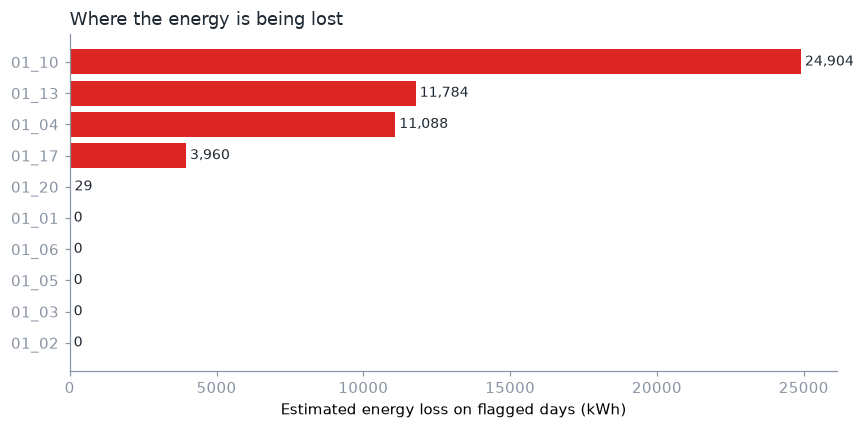

In [6]:
def plot_ranking(rank, path=None, top=10):
    r = rank.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.barh(r.index, r["loss_kwh"], color=[ALERT if v > 0 else MUTED for v in r["loss_kwh"]])
    for y, v in enumerate(r["loss_kwh"]):
        ax.text(v, y, f" {v:,.0f}", va="center", color=INK, fontsize=9)
    ax.set_xlabel("Estimated energy loss on flagged days (kWh)")
    ax.set_title("Where the energy is being lost")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()

plot_ranking(rank, "figures/ranking.png")

### Step report: one open string
Inverter `01_08` lost one string of about 20 on 2 June (5%). The daily rule does not fire,
but looking at the whole series finds the step, dates it and sizes it:

In [7]:
rank.loc[rank["step_date"].notna(), ["step_date", "step_pct", "pi_median", "flagged_days"]]

,step_date,step_pct,pi_median,flagged_days
inverter_id,,,,
01_13,2020-06-07,-14.7,0.912,13
01_08,2020-06-02,-4.9,0.961,0


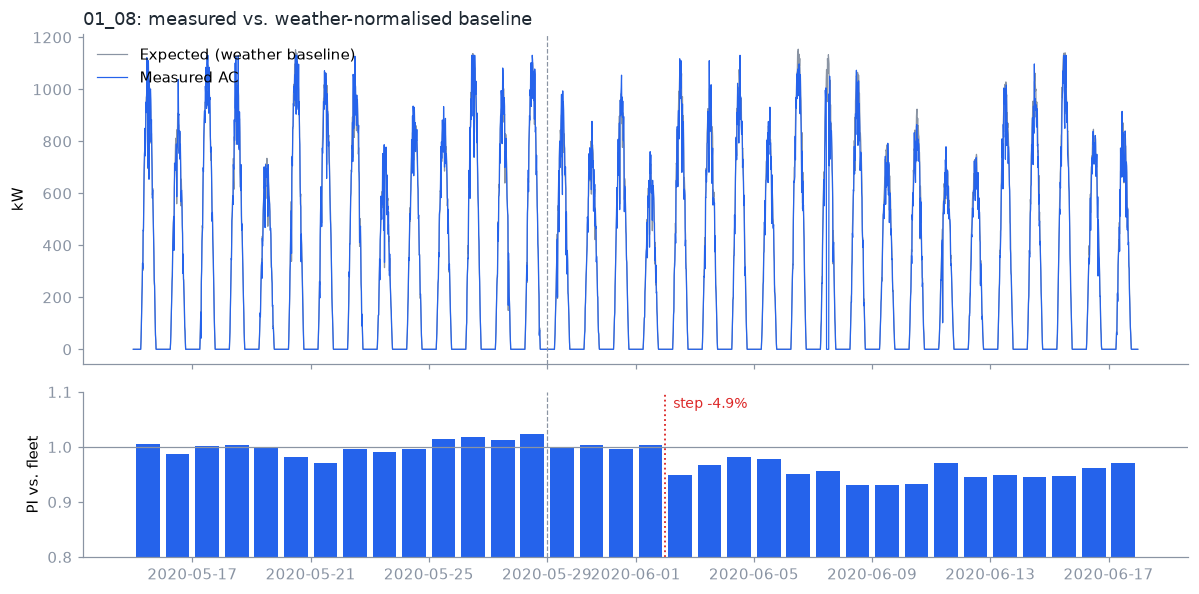

In [8]:
def plot_inverter(inv, path=None):
    g = scored[scored["inverter_id"] == inv]
    d = daily[daily["inverter_id"] == inv]
    step = rank.loc[inv, "step_date"]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1]})
    a1.plot(g["timestamp"], g["expected_ac_kw"], color=MUTED, lw=0.8, label="Expected (weather baseline)")
    a1.plot(g["timestamp"], g["ac_power_kw"], color=ACCENT, lw=0.8, label="Measured AC")
    a1.set_ylabel("kW")
    a1.set_title(f"{inv}: measured vs. weather-normalised baseline")
    a1.legend(frameon=False, loc="upper left")
    a2.bar(d["date"] + pd.Timedelta(hours=12), d["pi_vs_fleet"], width=0.8,
           color=[ALERT if a else ACCENT for a in d["anomaly"]])
    a2.axhline(1.0, color=MUTED, lw=0.8)
    a2.set_ylim(0.8, 1.1)
    a2.set_ylabel("PI vs. fleet")
    train_end = g.loc[g["is_train"], "timestamp"].max()
    for ax in (a1, a2):
        ax.axvline(train_end, color=MUTED, ls="--", lw=0.8)
    if pd.notna(step):
        a2.axvline(step, color=ALERT, ls=":", lw=1.2)
        a2.text(step, 1.09, f"  step {rank.loc[inv, 'step_pct']}%", color=ALERT, va="top", fontsize=9)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    plt.show()

plot_inverter("01_08", "figures/string_loss.png")

## 3 · Detection limit

How big must a loss be before it is caught? For each loss size, the synthetic plant is
run with 3 random seeds. The chart shows two things: the share of faulty days flagged by
the daily rules, and how often the step report dates the loss within one day.

In [9]:
rows = []
for loss in (0.02, 0.03, 0.05, 0.07, 0.10):
    for seed in range(3):
        d_, lab_ = pvad.synthetic_plant(seed=seed, string_loss=loss)
        _, day_ = pvad.run(d_)
        lab_ = lab_[lab_["fault_type"] == "string_loss"]
        flagged = day_.merge(lab_, on=["inverter_id", "date"])["anomaly"].mean()
        step = pvad.ranking(day_).loc["01_08", "step_date"]
        dated = pd.notna(step) and abs((step - lab_["date"].min()).days) <= 1
        rows.append({"loss_pct": loss * 100, "daily_rules": flagged, "step_report": dated})
curve = pd.DataFrame(rows).groupby("loss_pct").mean()
curve

,daily_rules,step_report
loss_pct,,
2.0,0.000,0.0
3.0,0.000,0.0
5.0,0.021,1.0
7.0,0.396,1.0
10.0,0.958,1.0


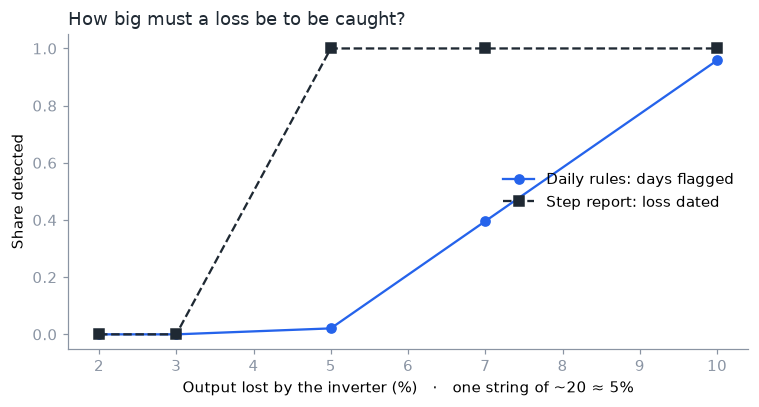

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve.index, curve["daily_rules"], color=ACCENT, marker="o", label="Daily rules: days flagged")
ax.plot(curve.index, curve["step_report"], color=INK, marker="s", ls="--", label="Step report: loss dated")
ax.set_xlabel("Output lost by the inverter (%)   ·   one string of ~20 ≈ 5%")
ax.set_ylabel("Share detected")
ax.set_ylim(-0.05, 1.05)
ax.set_title("How big must a loss be to be caught?")
ax.legend(frameon=False, loc="center right")
fig.tight_layout()
fig.savefig("figures/detection_limit.png")
plt.show()

The two layers work together:
- **Daily alarms** fire reliably from about **10%** loss, the size of a failed MPPT
  input or a few strings. They raise no false alarms, which is what makes them worth
  acting on.
- **The step report** dates a **single open string (5%)**.
- **Below ~4%**, the single weather sensor per plant sets the noise floor. Per-block
  irradiance would lower it.

## 4 · Real plants: Kaggle "Solar Power Generation Data"

There are no labels here, so the output is a ranking to investigate, not a score. First,
data quality:

In [11]:
plants = {p: pvad.load_kaggle(p) for p in (1, 2)}
pd.DataFrame({f"Plant {p}": pvad.data_quality(df) for p, df in plants.items()})

,Plant 1,Plant 2
inverters,22.00,22.00
days,34.00,34.00
missing_readings_pct,1.76,5.58
zero_ac_in_daylight_pct,0.20,12.32
median_dc_ac_ratio,10.21,1.02


- **Plant 1:** the DC column is ~10× AC, a known scaling issue in that file, which is
  why the model uses AC power.
- **Plant 2:** 12% of daylight readings are zero, so it needs a closer look.

In [12]:
results = {p: pvad.run(df) for p, df in plants.items()}
summary = {}
for p, (sc, d) in results.items():
    t = d[~d["is_train"]]
    summary[f"Plant {p}"] = {
        "flagged inverter-days": int(t["anomaly"].sum()),
        **{f"  {k}": v for k, v in t.loc[t["anomaly"], "reason"].value_counts().items()},
        "plant events (h)": pvad.plant_event_summary(sc)["hours"],
    }
rows = ["flagged inverter-days", "  zero output in daylight", "  no data",
        "  new fault vs own best days", "  chronic vs fleet", "plant events (h)"]
pd.DataFrame(summary).reindex(rows).fillna(0).astype(int)

,Plant 1,Plant 2
flagged inverter-days,8,149
zero output in daylight,6,131
no data,0,4
new fault vs own best days,2,7
chronic vs fleet,0,7
plant events (h),0,10


In [13]:
pvad.ranking(results[2][1]).head(6)

,flagged_days,loss_kwh,pi_median,chronic,step_date,step_pct
inverter_id,,,,,,
01_04,13,43504.0,0.672,True,2020-06-02,-5.8
01_14,11,40936.0,0.821,False,2020-05-25,-7.0
01_06,9,35769.0,0.961,False,2020-05-31,-3.2
01_12,17,35574.0,0.723,True,NaT,NaN
01_19,9,33816.0,0.966,False,NaT,NaN
01_03,9,32205.0,0.978,False,2020-05-19,-3.9


In Plant 2:
- **Two chronic inverters** (`01_04`, `01_12`, PI ~0.7) produce far below their peers.
- **10 hours of plant-wide drops** are reported once instead of as 22 alarms each.
- **131 outage days** stand out. Are they 131 separate trips?

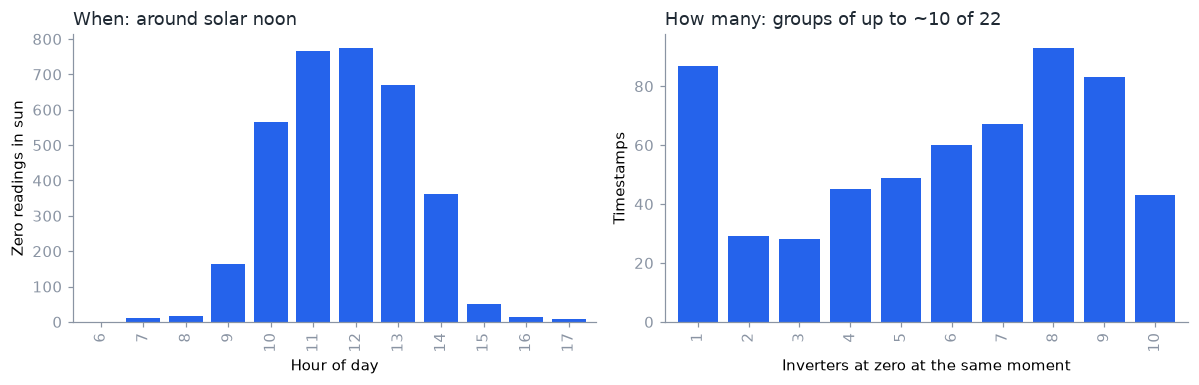

median irradiance during these zeros: 0.83 kW/m2


In [14]:
sc2 = results[2][0]
zero = sc2[(sc2["irradiation_kw_m2"] > pvad.DAYLIGHT_IRR) & (sc2["ac_power_kw"] <= 0) & ~sc2["plant_event"]]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
zero["timestamp"].dt.hour.value_counts().sort_index().plot.bar(ax=a1, color=ACCENT, width=0.8)
a1.set_xlabel("Hour of day")
a1.set_ylabel("Zero readings in sun")
a1.set_title("When: around solar noon")
zero.groupby("timestamp").size().value_counts().sort_index().plot.bar(ax=a2, color=ACCENT, width=0.8)
a2.set_xlabel("Inverters at zero at the same moment")
a2.set_ylabel("Timestamps")
a2.set_title("How many: groups of up to ~10 of 22")
fig.tight_layout()
fig.savefig("figures/plant2_zeros.png")
plt.show()
print(f"median irradiance during these zeros: {zero['irradiation_kw_m2'].median():.2f} kW/m2")

They are not random:
- **When:** at midday under strong sun.
- **How:** in **rotating groups of up to ~10 inverters** (about 45% of the plant).
- **How often:** almost every day.

This points to **export limitation (curtailment) or a recording issue**, not 131
independent trips. It is below the 80% rule, so the method keeps the alarms at inverter
level and leaves it to the engineer to confirm with SCADA or the grid operator.

**This is where topology pays off.** With the real `TT_II` map, if these groups share a
transformer or feeder, the same 80% rule applied one level down would report them as one
**transformer event** per day instead of ~4 inverter outages per day.

## 5 · Limitations and next steps

- **34 days of data:** no seasonality, and 14 days of history is the minimum for a
  stable baseline.
- **One irradiance sensor per plant:** this sets the ~4% noise floor.
- **No real topology in public data:** attribution above inverter level only works for
  plant-wide events.
- **Synthetic results** show the method works on the fault shapes injected. They are
  not a claim about any specific real plant.

**Next steps:**
- string level (`TT_II_SS`) with string-current data;
- the real transformer map;
- a rolling baseline that retrains weekly.